# J2 El Mantaro — pronóstico de heladas con variables de ECMWF

**Pregunta.** ¿Mejora nuestro modelo de heladas (boosting con estación, hoja y nubosidad) si le añadimos la **temperatura y el punto de rocío pronosticados por ECMWF**?

En `el_mantaro_comparacion_gfs_ecmwf.ipynb` vimos que ECMWF, por sí solo, tiene un sesgo cálido nocturno enorme (≈ +6 °C en las horas con helada), pero que su **punto de rocío** es bastante bueno y casi iguala al de la estación para anticipar el **tipo de helada**. Aquí no se usa ECMWF como pronóstico, sino como **predictor adicional**: el boosting puede aprender a corregir su sesgo y aprovechar lo que aporta.

**Variables de ECMWF añadidas** (IFS HRES 9 km, Historical Forecast API de Open-Meteo), todas conocidas en la hora de emisión *t*:
* T, Td y T − Td pronosticados en *t* y en cada hora *t+1 … t+6*;
* mínima de T, media de Td y de T − Td en las 6 h siguientes, y el enfriamiento previsto (T(t+6) − T(t));
* el **sesgo actual**: T de la estación − T de ECMWF en *t*, y la mínima de 6 h de ECMWF corregida con ese sesgo.

**Diseño de la comparación.**
* Dos variantes del mismo boosting: **base** (65 predictores, el modelo actual) y **+ ECMWF** (65 + 21).
* ECMWF solo tiene archivo desde **marzo de 2024**. Los dos modelos se entrenan con todos los años (en 2022–2023 las variables de ECMWF quedan vacías y el boosting las trata como faltantes) y se **evalúan solo en las horas desde 2024-03**, dejando un año fuera (2024, 2025 y 2026).
* Mismas métricas que antes: CSI, BSS y AUC, con bootstrap por noche para la diferencia; MAE y sesgo de la Tmin; y AUC para el tipo de helada.

**Advertencia.** Como en la comparación con ECMWF, el archivo une las primeras horas de corridas sucesivas, sin el retraso real de publicación (≈ 6 h para ECMWF). En operación, a la hora *t* solo se tendría una corrida algo más antigua, así que la mejora medida aquí es un **límite superior**.

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from sklearn.inspection import permutation_importance

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
EXT = BASE / 'data' / 'external'
OUT = BASE / 'resultados'; OUT.mkdir(exist_ok=True)

EST = 'j2_el_mantaro'
LAT, LON = -11.833526, -75.389548
UMBRALES = {'meteorologica': 0.0, 'agronomica': 2.0}
LEADS = list(range(1, 7))
LEADS_EVAL = [1, 3, 6, 'alerta6']
HORAS_EMISION = list(range(15, 24)) + list(range(0, 8))
UMB_MOJADO = 10
UMB_HIELO = 10
P_ALERTA = 0.5
N_BOOT = 1000
SEED = 42
rng = np.random.default_rng(SEED)
NUB_COLS = ['cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high']
INICIO_EC = pd.Timestamp('2024-03-01')

## 1. Datos de la estación y variables del modelo actual

Código copiado del notebook de nubosidad.

In [2]:
URL_HIST = ('https://historical-forecast-api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}'
            '&start_date={a}&end_date={b}&hourly=' + ','.join(NUB_COLS) + '&timezone=America%2FLima')

def descargar_nubosidad_hist(a, b, lat=LAT, lon=LON):
    j = json.load(urllib.request.urlopen(URL_HIST.format(lat=lat, lon=lon, a=a, b=b), timeout=120))
    df = pd.DataFrame(j['hourly']).rename(columns={'time': 'fecha'})
    df['fecha'] = pd.to_datetime(df['fecha'])
    return df.set_index('fecha')

CACHE = EXT / 'openmeteo_nubosidad_j2_el_mantaro.csv'
if CACHE.exists():
    NUB = pd.read_csv(CACHE, parse_dates=['fecha']).set_index('fecha')
else:
    NUB = pd.concat([descargar_nubosidad_hist(f'{y}-01-01', f'{y}-12-31') for y in range(2022, 2027)])
    NUB.reset_index().to_csv(CACHE, index=False)
print(NUB.index.min(), '->', NUB.index.max(), '| faltantes:', NUB.isna().sum().sum())
NUB.describe().round(1)

2022-03-01 00:00:00 -> 2026-10-31 23:00:00 | faltantes: 0


,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high
count,40944.0,40944.0,40944.0,40944.0
mean,66.5,27.3,32.9,48.9
std,37.1,33.2,33.7,43.3
min,0.0,0.0,0.0,0.0
25%,33.0,1.0,3.0,0.0
50%,85.0,13.0,21.0,47.0
75%,100.0,40.0,54.0,98.0
max,100.0,100.0,100.0,100.0


In [3]:
meta = pd.read_csv(DATA / 'estaciones.csv').set_index('estacion')
REN = {'temperatura_media': 'T', 'temperatura_minima': 'Tmin', 'temperatura_maxima': 'Tmax',
       'punto_rocio_medio': 'Td', 'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
       'velocidad_viento_maximo_1h': 'viento_max', 'precipitacion_acc_1h': 'pp',
       'radiacion_solar_media_1h': 'rad', 'rh_hoja_arriba_media_1h': 'arriba',
       'rh_hoja_bajo_media_1h': 'bajo', 'suelo_temperatura_5cm': 'Tsuelo5'}

def preparar(d):
    d = d.copy()
    if 'fecha' in d: d = d.set_index('fecha')
    d = d.rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    return d[list(REN.values())].asfreq('h')

def var_meteo(d):
    X = pd.DataFrame(index=d.index)
    for c in ['T', 'Tmin', 'Tmax', 'Td', 'HR', 'viento', 'viento_max', 'rad', 'Tsuelo5']:
        X[c] = d[c]
    X['dep'] = d['T'] - d['Td']
    for k in (1, 3, 6):
        X[f'dT_{k}h'] = d['T'] - d['T'].shift(k)
    X['dTd_3h'] = d['Td'] - d['Td'].shift(3)
    X['dHR_3h'] = d['HR'] - d['HR'].shift(3)
    X['viento_3h'] = d['viento'].rolling(3, min_periods=2).mean()
    X['pp_3h'] = d['pp'].rolling(3, min_periods=1).sum()
    X['pp_24h'] = d['pp'].rolling(24, min_periods=12).sum()
    X['Tmax_12h'] = d['Tmax'].rolling(12, min_periods=8).max()
    X['amplitud_12h'] = X['Tmax_12h'] - d['T']
    X['Tmin_24h'] = d['Tmin'].rolling(24, min_periods=12).min()
    rad24 = d['rad'].rolling(24, min_periods=18).sum()
    X['claridad_24h'] = rad24 / rad24.rolling('60D', min_periods=24 * 20).quantile(.95)
    X['suelo_menos_aire'] = d['Tsuelo5'] - d['T']
    h, doy = d.index.hour, d.index.dayofyear
    X['hora_sin'], X['hora_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return X

def linea_base_hoja(d):
    seco = d.index.hour.isin(range(11, 16)) & (d['pp'].fillna(0) == 0) & (d['HR'] < 60)
    rel = {}
    for k in ('arriba', 'bajo'):
        base = d[k].where(seco).rolling('30D', min_periods=20).median().shift(1).ffill()
        rel[k] = d[k] - base
    return rel

def var_hoja(d):
    X = pd.DataFrame(index=d.index)
    noche = (d.index - pd.Timedelta(hours=12)).normalize()
    rel = linea_base_hoja(d)
    for k in ('arriba', 'bajo'):
        r = rel[k]
        X[f'{k}_rel'] = r
        for L in (1, 3):
            X[f'{k}_d{L}h'] = r - r.shift(L)
        X[f'{k}_max3h'] = r.rolling(3, min_periods=2).max()
        moj = (r > UMB_MOJADO).astype(float).where(r.notna())
        X[f'{k}_horas_mojado'] = moj.fillna(0).groupby(noche).cumsum()
    X['arriba_menos_bajo'] = X['arriba_rel'] - X['bajo_rel']
    X['mojado_y_dep'] = X['arriba_rel'] / (1 + (d['T'] - d['Td']).clip(lower=0))
    return X

def var_nub(nub, idx, leads=LEADS):
    # nubosidad pronosticada en t y en las horas de validez t+1..t+6
    n = nub.reindex(idx)
    X = pd.DataFrame(index=idx)
    for c in NUB_COLS:
        X[f'{c}_t'] = n[c]
        fut = pd.concat([n[c].shift(-k) for k in leads], axis=1)
        X[f'{c}_med6h'] = fut.mean(axis=1)
        X[f'{c}_min6h'] = fut.min(axis=1)
    for k in leads:
        X[f'cc_t+{k}'] = n['cloud_cover'].shift(-k)
        X[f'ccl_t+{k}'] = n['cloud_cover_low'].shift(-k)
    X['cc_tendencia'] = n['cloud_cover'].shift(-6) - n['cloud_cover']
    X['cc_previa_6h'] = n['cloud_cover'].rolling(6, min_periods=3).mean()
    return X

D = preparar(pd.read_csv(DATA / 'horario' / f'{EST}.csv', parse_dates=['fecha']))
XM, XH, XN = var_meteo(D), var_hoja(D), var_nub(NUB, D.index)
F_METEO, F_HOJA, F_NUB = list(XM.columns), list(XH.columns), list(XN.columns)
ALL = XM.join(XH).join(XN)
for k in LEADS:
    ALL[f'y_T_{k}'] = D['Tmin'].shift(-k)
ALL['y_T_alerta6'] = pd.concat([D['Tmin'].shift(-k) for k in LEADS], axis=1).min(axis=1, skipna=False)
ALL['noche'] = (D.index - pd.Timedelta(hours=12)).normalize()
ALL['anio'] = D.index.year
print(len(F_METEO), 'meteo |', len(F_HOJA), 'hoja |', len(F_NUB), 'nubosidad')

27 meteo | 12 hoja | 26 nubosidad


## 2. Variables de ECMWF

In [4]:
URL_EC = ('https://historical-forecast-api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}'
          '&start_date={a}&end_date={b}&hourly=temperature_2m,dew_point_2m&models=ecmwf_ifs&timezone=America%2FLima')
CACHE_EC = EXT / 'openmeteo_ecmwf_ifs_t_td_j2_el_mantaro.csv'
if CACHE_EC.exists():
    EC = pd.read_csv(CACHE_EC, parse_dates=['fecha']).set_index('fecha')
else:
    partes = []
    for a, b in [('2024-03-01', '2024-12-31'), ('2025-01-01', '2025-12-31'), ('2026-01-01', '2026-10-31')]:
        j = json.load(urllib.request.urlopen(URL_EC.format(lat=LAT, lon=LON, a=a, b=b), timeout=180))
        partes.append(pd.DataFrame(j['hourly']))
    EC = pd.concat(partes).rename(columns={'time': 'fecha'})
    EC['fecha'] = pd.to_datetime(EC['fecha']); EC = EC.set_index('fecha')
    EC.reset_index().to_csv(CACHE_EC, index=False)
EC = EC.rename(columns={'temperature_2m': 'T', 'dew_point_2m': 'Td'})
EC = EC[EC.index >= INICIO_EC]
print(EC.index.min(), '->', EC.index.max(), '|', EC.notna().all(axis=1).sum(), 'horas con T y Td')

def var_ecmwf(ec, d, leads=LEADS):
    idx = d.index
    n = ec.reindex(idx)
    X = pd.DataFrame(index=idx)
    X['ec_T_t'], X['ec_Td_t'] = n['T'], n['Td']
    X['ec_dep_t'] = n['T'] - n['Td']
    T_f = pd.concat([n['T'].shift(-k) for k in leads], axis=1)
    Td_f = pd.concat([n['Td'].shift(-k) for k in leads], axis=1)
    for k in leads:
        X[f'ec_T_t+{k}'] = n['T'].shift(-k)
        X[f'ec_Td_t+{k}'] = n['Td'].shift(-k)
    X['ec_Tmin6h'] = T_f.min(axis=1, skipna=False)
    X['ec_Td_med6h'] = Td_f.mean(axis=1, skipna=False)
    X['ec_dep_med6h'] = (T_f.values - Td_f.values).mean(axis=1)
    X['ec_enfr6h'] = n['T'].shift(-6) - n['T']
    X['ec_sesgo_t'] = d['T'] - n['T']                       # estación − ECMWF, ahora
    X['ec_Tmin6h_corr'] = X['ec_Tmin6h'] + X['ec_sesgo_t']
    return X

XE = var_ecmwf(EC, D)
F_EC = list(XE.columns)
ALL = ALL.join(XE)
MUESTRA = ALL[ALL.index.hour.isin(HORAS_EMISION) & ALL['T'].notna() & ALL['Tmin'].notna()
              & ALL['arriba_rel'].notna() & ALL['bajo_rel'].notna() & ALL['cloud_cover_t'].notna()].copy()
F_BASE = F_METEO + F_HOJA + F_NUB
VARIANTES = {'base': F_BASE, '+ ECMWF': F_BASE + F_EC}
ANIOS = sorted(MUESTRA['anio'].unique())
ANIOS_EVAL = [a for a in ANIOS if a >= INICIO_EC.year]
print(len(F_EC), 'variables de ECMWF |', len(MUESTRA), 'horas de emisión |',
      int((MUESTRA.index >= INICIO_EC).sum()), 'desde 2024-03 |',
      f"{MUESTRA.loc[MUESTRA.index >= INICIO_EC, 'ec_Tmin6h'].notna().mean():.1%} de ellas con ECMWF completo")

2024-03-01 00:00:00 -> 2026-10-31 23:00:00 | 23400 horas con T y Td
21 variables de ECMWF | 26451 horas de emisión | 15089 desde 2024-03 | 100.0% de ellas con ECMWF completo


## 3. Probabilidad de helada y Tmin: base frente a + ECMWF

Para cada año de prueba (2024, 2025, 2026) se entrena con los demás años. Solo se evalúan las horas desde 2024-03.

In [5]:
def clf():
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
                                          l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                          random_state=SEED)
def reg():
    return HistGradientBoostingRegressor(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
                                         l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                         random_state=SEED)

OOF = {}
for lead in LEADS_EVAL:
    col = f'y_T_{lead}'
    sub = MUESTRA[MUESTRA[col].notna()]
    res = sub[['noche', 'anio', 'Tmin', col]].rename(columns={col: 'y_T'}).copy()
    for a in ANIOS_EVAL:
        tr, te = sub['anio'] != a, sub['anio'] == a
        for v, fs in VARIANTES.items():
            for nom_u, u in UMBRALES.items():
                y = sub[col] <= u
                res.loc[te, f'p_{v}_{nom_u}'] = clf().fit(sub.loc[tr, fs], y[tr]).predict_proba(sub.loc[te, fs])[:, 1]
            if lead != 'alerta6':
                res.loc[te, f'T_{v}'] = reg().fit(sub.loc[tr, fs], sub.loc[tr, col]).predict(sub.loc[te, fs])
    OOF[lead] = res[(res.index >= INICIO_EC) & sub.loc[res.index, 'ec_Tmin6h'].notna()]
    print('listo: plazo', lead, '|', len(OOF[lead]), 'horas evaluadas')

listo: plazo 1 | 15087 horas evaluadas


listo: plazo 3 | 15087 horas evaluadas


listo: plazo 6 | 15085 horas evaluadas


listo: plazo alerta6 | 15085 horas evaluadas


In [6]:
def csi(y, yh):
    a = (y & yh).sum(); b = (~y & yh).sum(); c = (y & ~yh).sum()
    return a / max(a + c, 1), b / max(a + b, 1), a / max(a + b + c, 1)

filas = []
for nom_u, u in UMBRALES.items():
    for lead, r in OOF.items():
        for casos in ('todos', 'inicio'):
            t = r if casos == 'todos' else r[r['Tmin'] > u]
            y = (t['y_T'] <= u).values
            bsc = brier_score_loss(y, np.full(len(y), y.mean()))
            for v in VARIANTES:
                p = t[f'p_{v}_{nom_u}'].values
                pod, far, c = csi(y, p >= P_ALERTA)
                filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos, 'variante': v, 'n_eventos': int(y.sum()),
                              'POD': pod, 'FAR': far, 'CSI': c, 'BSS': 1 - brier_score_loss(y, p) / bsc,
                              'AUC': roc_auc_score(y, p)})
MET = pd.DataFrame(filas)
MET.to_csv(OUT / 'el_mantaro_ecmwf_metricas.csv', index=False)
MET.pivot_table(index=['umbral', 'casos', 'plazo'], columns='variante', values=['CSI', 'BSS', 'POD', 'FAR'],
                sort=False)[[(k, v) for k in ('CSI', 'BSS', 'POD', 'FAR') for v in VARIANTES]].round(3)

CSI            BSS            POD            FAR        
variante                       base + ECMWF   base + ECMWF   base + ECMWF   base + ECMWF
umbral        casos  plazo                                                              
meteorologica todos  1        0.882   0.886  0.904   0.905  0.934   0.931  0.059   0.051
                     3        0.792   0.787  0.825   0.827  0.884   0.849  0.116   0.086
                     6        0.699   0.665  0.733   0.716  0.791   0.735  0.143   0.126
                     alerta6  0.750   0.752  0.773   0.765  0.839   0.822  0.123   0.102
              inicio 1        0.570   0.578  0.606   0.613  0.711   0.702  0.259   0.234
                     3        0.667   0.652  0.715   0.711  0.791   0.734  0.191   0.147
                     6        0.662   0.622  0.698   0.679  0.759   0.695  0.162   0.144
                     alerta6  0.626   0.625  0.651   0.640  0.741   0.716  0.199   0.169
agronomica    todos  1        0.891   0.889  0.904   0.905  0.934   0.928  0.049   0.046
                     3        0.776   0.768  0.787   0.793  0.879   0.863  0.131   0.126
                     6        0.667   0.668  0.698   0.691  0.773   0.754  0.171   0.146
                     alerta6  0.764   0.761  0.766   0.762  0.853   0.842  0.120   0.111
              inicio 1        0.589   0.572  0.620   0.623  0.704   0.674  0.217   0.209
                     3        0.640   0.619  0.649   0.657  0.779   0.744  0.218   0.213
                     6        0.616   0.619  0.648   0.641  0.730   0.711  0.203   0.172
                     alerta6  0.627   0.619  0.630   0.625  0.749   0.728  0.207   0.194

### 3.1 Diferencia + ECMWF − base (bootstrap por noche)

Positivo: ECMWF **mejora** el modelo. *mejor* / *peor* solo si el intervalo al 95 % no incluye 0.

In [7]:
def boot_diff(t, pa, pb, u):
    y = (t['y_T'] <= u).astype(float); yy = y.astype(bool)
    cols = {'n': 1.0, 'y': y, 'se_a': (t[pa] - y) ** 2, 'se_b': (t[pb] - y) ** 2}
    for s, c in (('a', pa), ('b', pb)):
        al = t[c] >= P_ALERTA
        cols[f'h_{s}'], cols[f'f_{s}'], cols[f'm_{s}'] = yy & al, ~yy & al, yy & ~al
    g = pd.DataFrame(cols, index=t.index).astype(float).groupby(t['noche']).sum()
    S = pd.DataFrame(rng.multinomial(len(g), np.ones(len(g)) / len(g), size=N_BOOT) @ g.values, columns=g.columns)
    clim = S['y'] / S['n']; bsc = (S['y'] * (1 - clim) ** 2 + (S['n'] - S['y']) * clim ** 2) / S['n']
    dbss = (S['se_b'] - S['se_a']) / S['n'] / bsc
    dcsi = S['h_a'] / (S['h_a'] + S['f_a'] + S['m_a']) - S['h_b'] / (S['h_b'] + S['f_b'] + S['m_b'])
    return dbss, dcsi

ic = lambda s: f'{s.median():+.3f} [{s.quantile(.025):+.3f}, {s.quantile(.975):+.3f}]'
sig = lambda s: 'mejor' if s.quantile(.025) > 0 else 'peor' if s.quantile(.975) < 0 else 'igual'
filas = []
for nom_u, u in UMBRALES.items():
    for lead, r in OOF.items():
        for casos in ('todos', 'inicio'):
            t = r if casos == 'todos' else r[r['Tmin'] > u]
            dbss, dcsi = boot_diff(t, f'p_+ ECMWF_{nom_u}', f'p_base_{nom_u}', u)
            filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos,
                          'ΔCSI': ic(dcsi), 'CSI': sig(dcsi), 'ΔBSS': ic(dbss), 'BSS': sig(dbss)})
BOOT = pd.DataFrame(filas)
BOOT.to_csv(OUT / 'el_mantaro_ecmwf_bootstrap.csv', index=False)
BOOT.set_index(['umbral', 'casos', 'plazo'])

ΔCSI    CSI                     ΔBSS    BSS
umbral        casos  plazo                                                                  
meteorologica todos  1        +0.004 [-0.007, +0.017]  igual  +0.001 [-0.004, +0.007]  igual
              inicio 1        +0.009 [-0.023, +0.041]  igual  +0.007 [-0.015, +0.030]  igual
              todos  3        -0.006 [-0.027, +0.015]  igual  +0.002 [-0.007, +0.013]  igual
              inicio 3        -0.014 [-0.049, +0.016]  igual  -0.003 [-0.020, +0.012]  igual
              todos  6        -0.034 [-0.065, -0.002]   peor  -0.017 [-0.040, +0.004]  igual
              inicio 6        -0.039 [-0.075, -0.001]   peor  -0.018 [-0.045, +0.009]  igual
              todos  alerta6  +0.001 [-0.016, +0.017]  igual  -0.008 [-0.022, +0.006]  igual
              inicio alerta6  -0.000 [-0.026, +0.024]  igual  -0.009 [-0.034, +0.015]  igual
agronomica    todos  1        -0.003 [-0.011, +0.006]  igual  +0.001 [-0.003, +0.005]  igual
              inicio 1        -0.016 [-0.053, +0.019]  igual  +0.003 [-0.015, +0.022]  igual
              todos  3        -0.008 [-0.024, +0.007]  igual  +0.006 [-0.004, +0.016]  igual
              inicio 3        -0.020 [-0.046, +0.005]  igual  +0.008 [-0.012, +0.029]  igual
              todos  6        +0.001 [-0.021, +0.022]  igual  -0.008 [-0.025, +0.009]  igual
              inicio 6        +0.003 [-0.019, +0.027]  igual  -0.008 [-0.026, +0.013]  igual
              todos  alerta6  -0.002 [-0.016, +0.011]  igual  -0.003 [-0.018, +0.010]  igual
              inicio alerta6  -0.008 [-0.028, +0.013]  igual  -0.005 [-0.027, +0.018]  igual

In [8]:
pd.concat({k: BOOT[k].value_counts() for k in ('CSI', 'BSS')}, axis=1).fillna(0).astype(int)

,CSI,BSS
igual,14,16
peor,2,0


### 3.2 Temperatura mínima: MAE y sesgo (pronóstico − observado)

In [9]:
filas = []
for lead in [1, 3, 6]:
    r = OOF[lead]
    for casos, t in (('todas', r), ('noches frías (Tmin ≤ 3 °C)', r[r['y_T'] <= 3]), ('horas con helada', r[r['y_T'] <= 0])):
        for v in VARIANTES:
            e = t[f'T_{v}'] - t['y_T']
            filas.append({'plazo': lead, 'casos': casos, 'variante': v, 'n': len(t), 'MAE': e.abs().mean(), 'sesgo': e.mean()})
TM = pd.DataFrame(filas)
TM.to_csv(OUT / 'el_mantaro_ecmwf_tmin.csv', index=False)
TM.pivot_table(index=['casos', 'plazo'], columns='variante', values=['MAE', 'sesgo'], sort=False)[
    [(k, v) for k in ('MAE', 'sesgo') for v in VARIANTES]].round(2)

MAE         sesgo        
variante                          base + ECMWF  base + ECMWF
casos                      plazo                            
todas                      1      0.58    0.57 -0.01   -0.01
                           3      0.98    0.96 -0.01   -0.00
                           6      1.17    1.14 -0.04   -0.01
noches frías (Tmin ≤ 3 °C) 1      0.33    0.33  0.09    0.08
                           3      0.75    0.73  0.50    0.46
                           6      1.13    1.12  0.84    0.80
horas con helada           1      0.31    0.30  0.08    0.06
                           3      0.56    0.51  0.37    0.27
                           6      0.90    0.82  0.66    0.47

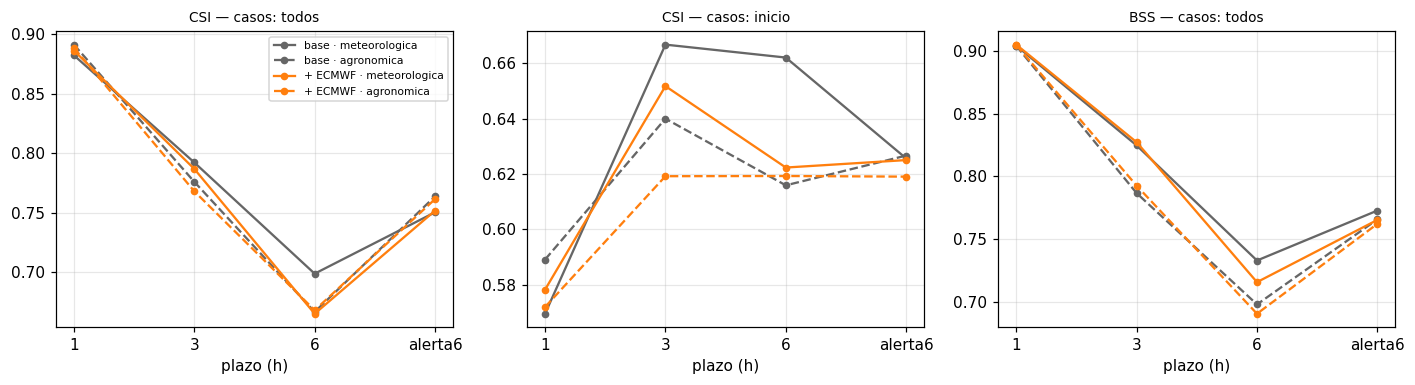

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
orden = [str(l) for l in LEADS_EVAL]
for ax, (k, casos) in zip(axs, [('CSI', 'todos'), ('CSI', 'inicio'), ('BSS', 'todos')]):
    for v, c in zip(VARIANTES, ('0.4', 'tab:orange')):
        for nom_u, ls in (('meteorologica', '-'), ('agronomica', '--')):
            g = MET[(MET.variante == v) & (MET.casos == casos) & (MET.umbral == nom_u)].set_index('plazo').loc[orden]
            ax.plot(orden, g[k], color=c, ls=ls, marker='o', ms=4, label=f'{v} · {nom_u}')
    ax.set_title(f'{k} — casos: {casos}', fontsize=9); ax.set_xlabel('plazo (h)')
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### 3.3 ¿Qué variables de ECMWF usa el modelo?

Importancia por permutación del clasificador de la alerta de 6 h (0 °C), entrenado con todos los años y medido sobre las horas desde 2024-03 (en muestra: orienta, no mide acierto).

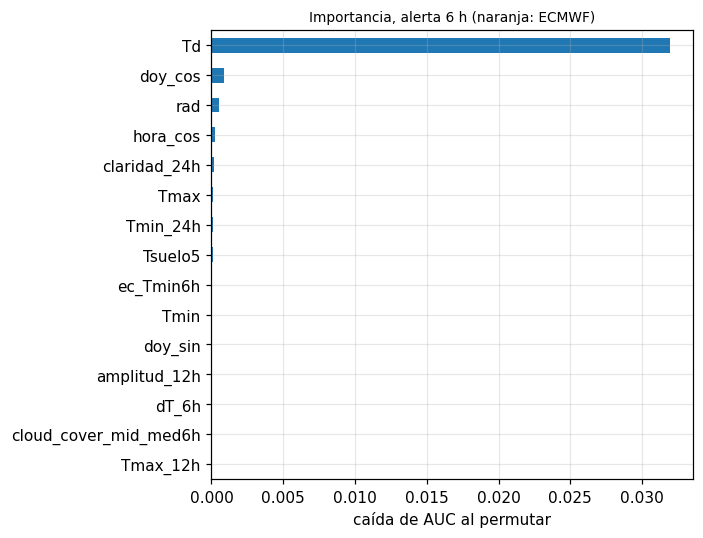

In [11]:
col = 'y_T_alerta6'
sub = MUESTRA[MUESTRA[col].notna()]
m = clf().fit(sub[VARIANTES['+ ECMWF']], sub[col] <= 0)
ev = sub[(sub.index >= INICIO_EC) & sub['ec_Tmin6h'].notna()]
pi = permutation_importance(m, ev[VARIANTES['+ ECMWF']], ev[col] <= 0, scoring='roc_auc', n_repeats=5,
                            random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=VARIANTES['+ ECMWF']).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(6.5, 5))
imp.plot.barh(ax=ax, color=['tab:orange' if f in F_EC else 'tab:blue' for f in imp.index])
ax.set_title('Importancia, alerta 6 h (naranja: ECMWF)', fontsize=9); ax.set_xlabel('caída de AUC al permutar')
plt.tight_layout(); plt.show()

## 4. Tipo de helada: ¿anticipa mejor si la helada será negra?

Entre las horas de emisión en que **sí habrá helada** en *t+h* (desde 2024-03, con ECMWF), se compara:

* **logística simple** (Td, T − Td de la estación y nubosidad media de 6 h), el mejor modelo de tipo en `el_mantaro_comparacion_modelos.ipynb`;
* **logística simple + ECMWF**: añade el Td medio y la depresión T − Td media que ECMWF pronostica para las 6 h siguientes;
* **boosting** con los 65 predictores y **boosting + ECMWF**.

Todos con pesos balanceados. Como las logísticas no aceptan faltantes, los cuatro modelos se entrenan **solo con horas desde 2024-03** (con ECMWF), dejando un año fuera entre 2024, 2025 y 2026. Hay pocas heladas negras, así que los intervalos son amplios.

In [12]:
REL = linea_base_hoja(D)
noche_s = ALL['noche']
h = D.index.hour
es_noche = (h >= 18) | (h <= 8)
fh = D[es_noche & (D['Tmin'] <= 0)].copy()
fh['senal'] = pd.concat([REL['arriba'], REL['bajo']], axis=1).max(axis=1).reindex(fh.index)
fh['noche'] = noche_s.reindex(fh.index)
fh['dep'] = fh['T'] - fh['Td']
NOCH = fh.groupby('noche').agg(horas_bajo0=('Tmin', 'size'), tmin=('Tmin', 'min'), senal_max=('senal', 'max'),
                               senal_med=('senal', 'median'), dep_med=('dep', 'median'), hr_max=('HR', 'max'),
                               td_min=('Td', 'min'), viento=('viento', 'mean'))
nub_noche = NUB.reindex(D.index[es_noche]).groupby(noche_s.reindex(D.index[es_noche])).mean()
NOCH = NOCH.join(nub_noche)
NOCH['tipo_hoja'] = np.select([NOCH['senal_max'].isna(), NOCH['senal_max'] >= UMB_HIELO], ['sin dato', 'blanca'], 'negra')
# heurística de Td (primer notebook), en la hora de la Tmin
idx_min = fh.groupby('noche')['Tmin'].idxmin()
td_m, dep_m = D.loc[idx_min.values, 'Td'].values, (D['T'] - D['Td']).loc[idx_min.values].values
NOCH['tipo_td'] = np.where((td_m <= 0) & (dep_m <= 3), 'blanca', 'negra')
print(NOCH['tipo_hoja'].value_counts())
pd.crosstab(NOCH['tipo_hoja'], NOCH['tipo_td'], margins=True)

tipo_hoja
blanca    244
negra      24
Name: count, dtype: int64


tipo_td,blanca,negra,All
tipo_hoja,,,
blanca,229,15,244
negra,16,8,24
All,245,23,268


In [13]:
TIPO = NOCH['tipo_hoja'].to_dict()
F_SIMPLE = ['Td', 'dep', 'cloud_cover_med6h']
F_SIMPLE_EC = F_SIMPLE + ['ec_Td_med6h', 'ec_dep_med6h']
logit = lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                              LogisticRegression(class_weight='balanced', max_iter=3000))
hgb_t = lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                                               l2_regularization=2.0, class_weight='balanced', random_state=SEED)
MODELOS_TIPO = {'logística simple': (logit, F_SIMPLE), 'logística simple + ECMWF': (logit, F_SIMPLE_EC),
                'boosting': (hgb_t, F_BASE), 'boosting + ECMWF': (hgb_t, F_BASE + F_EC)}

def boot_auc(s, col):
    grupos = [(g['y_negra'].values, g[col].values) for _, g in s.groupby('noche_obj')]
    out = []
    for _ in range(N_BOOT):
        sel = rng.integers(0, len(grupos), len(grupos))
        y = np.concatenate([grupos[i][0] for i in sel]); p = np.concatenate([grupos[i][1] for i in sel])
        if len(np.unique(y)) == 2:
            out.append(roc_auc_score(y, p))
    return np.quantile(out, [.025, .975])

filas = []
for lead in [3, 'alerta6']:
    col = f'y_T_{lead}'
    sub = MUESTRA[(MUESTRA[col] <= 0) & (MUESTRA.index >= INICIO_EC) & MUESTRA['ec_Td_med6h'].notna()].copy()
    h_obj = sub.index + pd.Timedelta(hours=6 if lead == 'alerta6' else lead)
    sub['noche_obj'] = (h_obj - pd.Timedelta(hours=12)).normalize()
    sub['tipo'] = sub['noche_obj'].map(TIPO)
    sub = sub[sub['tipo'].isin(['blanca', 'negra'])]
    sub['y_negra'] = sub['tipo'] == 'negra'
    for m in MODELOS_TIPO: sub[f'p_{m}'] = np.nan
    for a in ANIOS_EVAL:
        tr, te = sub['anio'] != a, sub['anio'] == a
        if te.sum() == 0 or sub.loc[tr, 'y_negra'].sum() < 5: continue
        for m, (f, fs) in MODELOS_TIPO.items():
            sub.loc[te, f'p_{m}'] = f().fit(sub.loc[tr, fs], sub.loc[tr, 'y_negra']).predict_proba(sub.loc[te, fs])[:, 1]
    s = sub.dropna(subset=[f'p_{m}' for m in MODELOS_TIPO])
    for m in MODELOS_TIPO:
        lo, hi = boot_auc(s, f'p_{m}')
        filas.append({'plazo': str(lead), 'modelo': m, 'horas': len(s), 'noches negras': s.loc[s.y_negra, 'noche_obj'].nunique(),
                      'AUC': roc_auc_score(s['y_negra'], s[f'p_{m}']), 'IC 95 %': f'[{lo:.3f}, {hi:.3f}]',
                      'exactitud balanceada': balanced_accuracy_score(s['y_negra'], s[f'p_{m}'] >= 0.5)})
MET_T = pd.DataFrame(filas)
MET_T.to_csv(OUT / 'el_mantaro_ecmwf_tipo.csv', index=False)
MET_T.round(3)

,plazo,modelo,horas,noches negras,AUC,IC 95 %,exactitud balanceada
0,3,logística simple,578,15,0.879,"[0.795, 0.938]",0.785
1,3,logística simple + ECMWF,578,15,0.882,"[0.796, 0.946]",0.768
2,3,boosting,578,15,0.821,"[0.721, 0.906]",0.681
3,3,boosting + ECMWF,578,15,0.774,"[0.663, 0.872]",0.616
4,alerta6,logística simple,1148,15,0.841,"[0.740, 0.917]",0.775
5,alerta6,logística simple + ECMWF,1148,15,0.831,"[0.731, 0.905]",0.775
6,alerta6,boosting,1148,15,0.706,"[0.576, 0.815]",0.580
7,alerta6,boosting + ECMWF,1148,15,0.706,"[0.595, 0.809]",0.567


## 5. Conclusiones

**Añadir ECMWF no mejora el modelo de heladas.**

* **Probabilidad de helada.** En las 16 combinaciones (umbral × plazo × casos), la versión + ECMWF es **igual** a la base en BSS en las 16, e igual en CSI en 14. En las otras 2 es algo **peor**: a 6 h con el umbral de 0 °C, el CSI baja de 0.70 a 0.67 (todos los casos) y de 0.66 a 0.62 (casos de inicio), porque el modelo se vuelve más conservador (menos falsas alarmas, pero también menos heladas detectadas).
* **Temperatura mínima.** Mejora poco, pero en la dirección correcta: en las horas con helada, el sesgo cálido a 6 h baja de +0.66 a +0.47 °C y el error medio de 0.90 a 0.82 °C. En el conjunto de horas la diferencia es de centésimas.
* **Tipo de helada.** Tampoco mejora: la logística simple tiene AUC 0.88 a 3 h con o sin ECMWF, y en la alerta de 6 h 0.84 frente a 0.83. Las variantes con boosting, entrenadas solo con 2024–2026, quedan por debajo (0.71–0.82), lo que confirma que con tan pocas heladas negras (15 noches) un modelo simple es mejor.
* **Importancia.** El modelo casi no usa las variables de ECMWF: la que más pesa, la mínima prevista para las 6 h siguientes, queda muy por detrás de las variables de la estación.

**Por qué.**
1. **La estación ya sabe lo que ECMWF podría aportar** a 1–6 h: el enfriamiento en curso, la humedad real y la nubosidad (que ya entra por Open-Meteo). En el notebook de comparación, el punto de rocío de ECMWF casi igualaba al de la estación, pero no lo superaba: es información redundante.
2. **Pocos datos con ECMWF.** Solo hay archivo desde 2024-03. En cada fold, el modelo aprende de ECMWF con apenas dos temporadas, y el resto del entrenamiento lo ve como faltante.
3. El resultado medido además es **optimista** para ECMWF (sin el retraso real de publicación), así que en operación lo esperable es aún menos.

**Recomendación.** No añadir ECMWF al modelo operativo de 1–6 h: complicaría la operación (otra descarga en tiempo real) sin mejorar el acierto. Donde ECMWF sí podría aportar es en **plazos más largos (12–24 h)**, por ejemplo un aviso por la tarde para la noche siguiente, cuando la estación todavía no ha empezado a enfriarse; conviene revisarlo cuando haya más temporadas con ECMWF archivado.
